# 03_1_ModelTraining Notebook

In this notebook the prepared data is loaded and used for model training.

This notebook is used to train regression models combined inputs of images and meta data.

## 1. Import libaries and define parameters

In [1]:
import os
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error
from PIL import Image

import torch
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
from torch import nn, optim
import torchvision.models as models
from torchvision import transforms
from torchinfo import summary

In [2]:
goldDir = r'C:\Users\domin\OneDrive\Dokumente\Privat\AlgaeBiotech\IGB-Sensorfusion\Data\03_gold'
imageDir = r'C:\Users\domin\OneDrive\Dokumente\Privat\AlgaeBiotech\IGB-Sensorfusion\Data\02_silver2'
trainDataFile = r'\combinedTrainData.xlsx'
testDataFile = r'\combinedTestData.xlsx'

metaFeatures = ['probeQuantity','iso']
label = 'concentration'

batchSize = 32
num_epochs = 500

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## 2. Load data and prepare for training

In [4]:
class ImageMetadataDataset(Dataset):
    def __init__(self, excel_path, image_dir, transform=None):
        self.data = pd.read_excel(excel_path)
        self.image_dir = image_dir
        self.transform = transform

        # Identify columns
        self.image_column = 'imgFileName'
        self.label_column = 'concentration'
        self.metadata_columns = metaFeatures

        # Normalize metadata (optional: scale for training stability)
        self.data[self.metadata_columns] = (
            self.data[self.metadata_columns] - self.data[self.metadata_columns].mean()
        ) / self.data[self.metadata_columns].std()

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]

        # Load image
        image_path = os.path.join(self.image_dir, row[self.image_column])
        image = Image.open(image_path).convert("RGB")
        if self.transform:
            image = self.transform(image)

        # Load metadata and label
        metadata = row[self.metadata_columns].astype(float).values
        metadata = torch.tensor(metadata, dtype=torch.float32)
        label = torch.tensor(row[self.label_column], dtype=torch.float32)

        return image, metadata, label

In [5]:
image_transforms = transforms.Compose([
    transforms.ToTensor()#,  # Converts to [0,1]
])

In [6]:
train_dataset = ImageMetadataDataset(goldDir + trainDataFile, imageDir, transform=image_transforms)
test_dataset = ImageMetadataDataset(goldDir + testDataFile, imageDir, transform=image_transforms)

train_loader = DataLoader(train_dataset, batch_size=batchSize, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batchSize, shuffle=False)

# Example batch
for image_batch, metadata_batch, label_batch in train_loader:
    print("Image shape:", image_batch.shape)       # (B, 3, W, H)
    print("Metadata shape:", metadata_batch.shape) # (B, metadata_dim)
    print("Label shape:", label_batch.shape)       # (B,)
    break

Image shape: torch.Size([32, 3, 120, 120])
Metadata shape: torch.Size([32, 2])
Label shape: torch.Size([32])


## 3. Define and train model

The idea is to use a multimodal neural network with a CNN for image processing and a MLP fo the metadata. The outputs of both are concatenated and then a final regression layer creates the regression output.

### Model definition

In [7]:
class ColorCNN(nn.Module):
    def __init__(self):
        super(ColorCNN, self).__init__()

        self.conv_block = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),  # 120 → 60
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),  # 60 → 30
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1))  # [B, 64, 1, 1]
        )

        self.feature_dim = 64  # Output dim after pooling

    def forward(self, x):
        x = self.conv_block(x)
        return x.view(x.size(0), -1)  # [B, 64]

In [8]:
class CombinedRegressor(nn.Module):
    def __init__(self, metadata_dim):
        super(CombinedRegressor, self).__init__()

        # Image CNN
        self.image_model = ColorCNN()
        image_out_dim = self.image_model.feature_dim  # 64

        # Metadata model
        self.meta_model = nn.Sequential(
            nn.Linear(metadata_dim, 8),
            nn.ReLU(),
            nn.Linear(8, 4),
            nn.ReLU()
        )
        meta_out_dim = 4

        # Combined regressor
        self.regressor = nn.Sequential(
            nn.Linear(image_out_dim + meta_out_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, 1)
        )

    def forward(self, image, metadata):
        img_feat = self.image_model(image)        # [B, 64]
        meta_feat = self.meta_model(metadata)     # [B, 16]
        combined = torch.cat([img_feat, meta_feat], dim=1)  # [B, 80]
        return self.regressor(combined)           # [B, 1]

In [9]:
# --- Define model ---
metadata_dim = len(train_dataset.metadata_columns)
image_size = np.array(image_batch).shape[1:]
model = CombinedRegressor(metadata_dim=metadata_dim).to(device)
# --- Loss and optimizer ---
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=1e-4)

In [10]:
summary(model, input_data=[torch.randn(1, *image_size).to(device), torch.randn(1, metadata_dim).to(device)])

Layer (type:depth-idx)                   Output Shape              Param #
CombinedRegressor                        [1, 1]                    --
├─ColorCNN: 1-1                          [1, 64]                   --
│    └─Sequential: 2-1                   [1, 64, 1, 1]             --
│    │    └─Conv2d: 3-1                  [1, 16, 120, 120]         448
│    │    └─ReLU: 3-2                    [1, 16, 120, 120]         --
│    │    └─MaxPool2d: 3-3               [1, 16, 60, 60]           --
│    │    └─Conv2d: 3-4                  [1, 32, 60, 60]           4,640
│    │    └─ReLU: 3-5                    [1, 32, 60, 60]           --
│    │    └─MaxPool2d: 3-6               [1, 32, 30, 30]           --
│    │    └─Conv2d: 3-7                  [1, 64, 30, 30]           18,496
│    │    └─ReLU: 3-8                    [1, 64, 30, 30]           --
│    │    └─AdaptiveAvgPool2d: 3-9       [1, 64, 1, 1]             --
├─Sequential: 1-2                        [1, 4]                    --
│    └─

### Model training

In [11]:
def evaluate(model, dataloader, criterion, device):
    model.eval()
    total_loss = 0
    with torch.no_grad():
        for images, metadata, targets in dataloader:
            images = images.to(device)
            metadata = metadata.to(device)
            targets = targets.to(device).unsqueeze(1)

            outputs = model(images, metadata)
            loss = criterion(outputs, targets)
            total_loss += loss.item()
    avg_loss = total_loss / len(dataloader)
    return avg_loss

In [12]:
# early stopping definition
best_val_loss = float('inf')
patience = 5  # Number of epochs to wait before stopping
counter = 0   # Tracks how many epochs have passed without improvement

In [13]:
# training loop
start_time = time.time()

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0

    for images, metadata, targets in train_loader:
        images = images.to(device)
        metadata = metadata.to(device)
        targets = targets.to(device).unsqueeze(1)  # shape (B,) → (B,1)

        # Forward
        outputs = model(images, metadata)
        loss = criterion(outputs, targets)

        # Backward
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    train_loss = running_loss / len(train_loader)
    val_loss = evaluate(model, test_loader, criterion, device)
    print(f"Epoch {epoch+1} - Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}")

    # check for early stopping
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        counter = 0
        # Save model
        torch.save(model.state_dict(), "best_model.pth")
        print("Validation loss improved. Model saved.")
    elif best_val_loss < 0.3:
        counter += 1
        print(f"No improvement. Early stop counter: {counter}/{patience}")
        if counter >= patience:
            print("Early stopping triggered.")
            break

# evaluate time of training
elapsed_time = time.time() - start_time

print(f"Training took {elapsed_time:.2f} seconds ({elapsed_time/60:.2f} minutes)")

Epoch 1 - Train Loss: 13.5309, Val Loss: 12.8395
Validation loss improved. Model saved.
Epoch 2 - Train Loss: 13.9587, Val Loss: 12.8187
Validation loss improved. Model saved.
Epoch 3 - Train Loss: 14.5130, Val Loss: 12.7968
Validation loss improved. Model saved.
Epoch 4 - Train Loss: 14.1955, Val Loss: 12.7739
Validation loss improved. Model saved.
Epoch 5 - Train Loss: 13.4517, Val Loss: 12.7501
Validation loss improved. Model saved.
Epoch 6 - Train Loss: 13.3405, Val Loss: 12.7250
Validation loss improved. Model saved.
Epoch 7 - Train Loss: 14.5228, Val Loss: 12.6982
Validation loss improved. Model saved.
Epoch 8 - Train Loss: 13.9681, Val Loss: 12.6690
Validation loss improved. Model saved.
Epoch 9 - Train Loss: 14.8593, Val Loss: 12.6376
Validation loss improved. Model saved.
Epoch 10 - Train Loss: 13.1564, Val Loss: 12.6036
Validation loss improved. Model saved.
Epoch 11 - Train Loss: 14.4678, Val Loss: 12.5675
Validation loss improved. Model saved.
Epoch 12 - Train Loss: 13.0449

## 4. Evaluate model performance

In [14]:
def evaluate_and_collect_outputs(model, dataloader, device):
    model.eval()
    all_outputs = []
    all_targets = []
    with torch.no_grad():
        for images, metadata, targets in dataloader:
            images = images.to(device)
            metadata = metadata.to(device)
            targets = targets.to(device).unsqueeze(1)

            outputs = model(images, metadata)

            all_outputs.append(outputs.cpu())
            all_targets.append(targets.cpu())

    # Concatenate all batches
    all_outputs = torch.cat(all_outputs).squeeze().numpy()  # shape (N,)
    all_targets = torch.cat(all_targets).squeeze().numpy()  # shape (N,)
    return all_outputs, all_targets

In [15]:
# load best model from training for evaluation
model.load_state_dict(torch.load("best_model.pth", weights_only=True))

<All keys matched successfully>

### Training peformnace

In [16]:
outputs, targets = evaluate_and_collect_outputs(model, train_loader, device)

In [17]:
mae = mean_absolute_error(targets, outputs)
rmse = np.sqrt(mean_squared_error(targets, outputs))
print(f"MAE: {mae:.4f}, RMSE: {rmse:.4f}")

MAE: 0.3565, RMSE: 0.4856


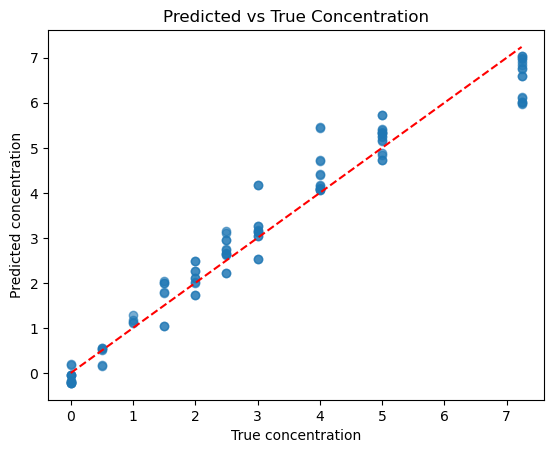

In [18]:
plt.scatter(targets, outputs, alpha=0.6)
plt.plot([targets.min(), targets.max()], [targets.min(), targets.max()], 'r--')  # diagonal line
plt.xlabel("True concentration")
plt.ylabel("Predicted concentration")
plt.title("Predicted vs True Concentration")
plt.show()

### Testing performance

In [19]:
outputs, targets = evaluate_and_collect_outputs(model, test_loader, device)

In [20]:
mae = mean_absolute_error(targets, outputs)
rmse = np.sqrt(mean_squared_error(targets, outputs))
print(f"MAE: {mae:.4f}, RMSE: {rmse:.4f}")

MAE: 0.5040, RMSE: 0.5713


In [21]:
# Get unique target values
unique_targets = np.unique(targets)
# Store stats
means = []
stds = []

# Calculate mean and std for each unique target value
for t in unique_targets:
    preds_for_t = outputs[targets == t]
    means.append(np.mean(preds_for_t))
    stds.append(np.std(preds_for_t))

In [22]:
for i in range(len(unique_targets)):
    print(f"Mean and Standard deviation of predictions for target {unique_targets[i]:.4f}: \n mean error: {abs(means[i]-unique_targets[i]):.4f}\n std : {stds[i]:.4f}, 3std: {3*stds[i]:.4f},")

Mean and Standard deviation of predictions for target 0.2400: 
 mean error: 0.2056
 std : 0.2502, 3std: 0.7505,
Mean and Standard deviation of predictions for target 1.2300: 
 mean error: 0.2964
 std : 0.4862, 3std: 1.4585,
Mean and Standard deviation of predictions for target 5.1300: 
 mean error: 0.3838
 std : 0.5944, 3std: 1.7831,


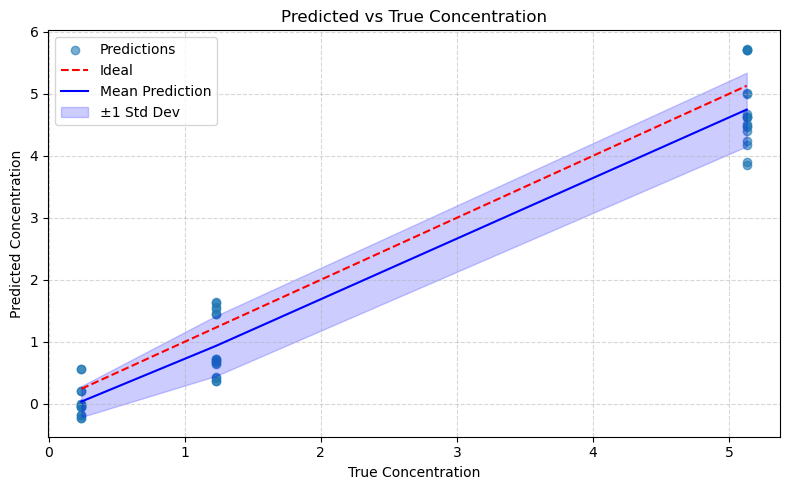

In [23]:
mean_preds = np.array(means)
std_preds = np.array(stds)

plt.figure(figsize=(8, 5))

# Scatter of actual predictions
plt.scatter(targets, outputs, alpha=0.6, label="Predictions")

# Diagonal line: perfect prediction
plt.plot([targets.min(), targets.max()], [targets.min(), targets.max()], 'r--', label="Ideal")

# Tube (±1 std around the mean prediction for each class)
plt.plot(unique_targets, mean_preds, 'b-', label="Mean Prediction")
#plt.fill_between(unique_targets, mean_preds - 3*std_preds, mean_preds + 3*std_preds,
#                 color='green', alpha=0.2, label="±3 Std Dev")
plt.fill_between(unique_targets, mean_preds - std_preds, mean_preds + std_preds,
                 color='blue', alpha=0.2, label="±1 Std Dev")

plt.xlabel("True Concentration")
plt.ylabel("Predicted Concentration")
plt.title("Predicted vs True Concentration")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()